# Question 1 – Part A  
## Exploratory Data Analysis (EDA)

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")


In [18]:
#loading our train data
df = pd.read_csv("../data/train.csv")
df.head(10)


,neighbourhood_group,room_type,minimum_nights,amenity_score,number_of_reviews,availability_365,price_class
0,Manhattan,NaN,2.0,82.5,15.0,254.0,3
1,Manhattan,Private room,2.0,53.7,1.0,0.0,1
2,Brooklyn,Private room,2.0,47.8,70.0,90.0,1
3,Manhattan,Entire home/apt,2.0,58.8,1.0,NaN,1
4,Bronx,Private room,2.0,32.2,0.0,89.0,1
5,Manhattan,Private room,5.0,48.6,2.0,6.0,1
6,Manhattan,Private room,2.0,11.5,12.0,45.0,0
7,Manhattan,Entire home/apt,2.0,84.9,9.0,0.0,2
8,Brooklyn,Entire home/apt,2.0,44.2,23.0,190.0,1
9,Manhattan,Entire home/apt,30.0,27.7,3.0,82.0,0


In [19]:
#shape of our data
print("Shape of the dataset = ", df.shape)

Shape of the dataset =  (41348, 7)


### about dataset shape

The dataset contains **41348 samples rows** and **7 columns features including target variable**.


In [20]:
#data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 41348 entries, 0 to 41347
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   neighbourhood_group  40509 non-null  str    
 1   room_type            40737 non-null  str    
 2   minimum_nights       40026 non-null  float64
 3   amenity_score        40432 non-null  float64
 4   number_of_reviews    40225 non-null  float64
 5   availability_365     40753 non-null  float64
 6   price_class          41348 non-null  int64  
dtypes: float64(4), int64(1), str(2)
memory usage: 2.2 MB


### Data Types

- Categorical Features: neighbourhood_group, room_type  
- Numerical Features: minimum_nights, amenity_score, number_of_reviews, availability_365  
- Target Variable: price_class (multi-class classification with 4 categories)



In [21]:
df.isnull().sum()


neighbourhood_group     839
room_type               611
minimum_nights         1322
amenity_score           916
number_of_reviews      1123
availability_365        595
price_class               0
dtype: int64

In [22]:
categorical_cols = ["neighbourhood_group", "room_type"]

# fill missing values in categorical columns with the mode
for col in categorical_cols:
    df[col] = df[col].replace("", np.nan)
    df[col] = df[col].fillna(df[col].mode()[0])

numeric_cols = ["minimum_nights", "amenity_score", "number_of_reviews", "availability_365"]

# fill missing values in numeric columns with the median
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
neighbourhood_group    0
room_type              0
minimum_nights         0
amenity_score          0
number_of_reviews      0
availability_365       0
price_class            0
dtype: int64


### Missing Values Handling

- Categorical missing values were replaced with the mode 
- Numerical missing values were imputed using the median


In [23]:
# class distribution
df["price_class"].value_counts()


price_class
1    23287
2     9844
0     5567
3     2650
Name: count, dtype: int64

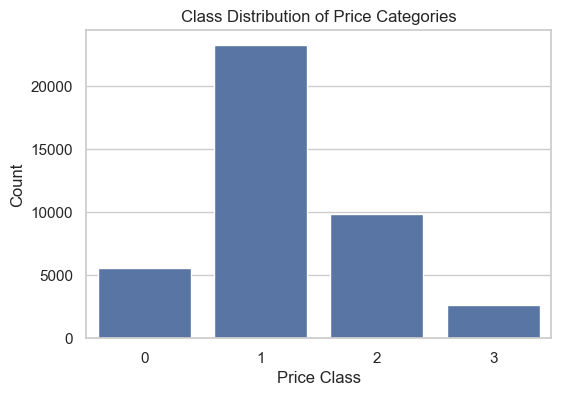

In [24]:
plt.figure(figsize=(6,4))
sns.countplot(x="price_class", data=df)
plt.title("Class Distribution of Price Categories")
plt.xlabel("Price Class")
plt.ylabel("Count")
plt.show()


### Class Distribution Analysis

- 0 = Budget  
- 1 = Moderate  
- 2 = Premium  
- 3 = Luxury

Observations:
- The dataset has a slight imbalance as we can see that moderate (1) dominates with 23287 listings.
- Neural network may favor majority class, which can be addressed later if we need


In [26]:
#standardization
from sklearn.preprocessing import StandardScaler
import joblib

numeric_cols = ["minimum_nights", "amenity_score", "number_of_reviews", "availability_365"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

#  Standardizing numeric features
scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

joblib.dump(scaler, "../data/scaler.pkl")
#  Encoding categorical features
categorical_cols = ["neighbourhood_group", "room_type"]
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=False)
df_encoded.to_csv("../data/df_encoded.csv", index=False)

print(df_encoded.head())
print(df_encoded.dtypes)

   minimum_nights  amenity_score  number_of_reviews  availability_365  \
0       -0.251024       1.586358          -0.184981          1.095654   
1       -0.251024       0.089685          -0.503065         -0.849587   
2       -0.251024      -0.216925           1.064634         -0.160329   
3       -0.251024       0.354721          -0.503065         -0.512616   
4       -0.251024      -1.027623          -0.525785         -0.167987   

   price_class  neighbourhood_group_Bronx  neighbourhood_group_Brooklyn  \
0            3                      False                         False   
1            1                      False                         False   
2            1                      False                          True   
3            1                      False                         False   
4            1                       True                         False   

   neighbourhood_group_Manhattan  neighbourhood_group_Queens  \
0                           True              

#### Categorical Encoding Strategy

- One-hot encoding converts categorical variables into numerical format. like true/false format  where present
- Since number of categories is small, dimensionality increase is not an issue.  
- Neural network treats each category independently.


#### Normalization of Numerical Features

- StandardScaler was used to normalize numerical features.
- This method transforms features to have **mean = 0** and **standard deviation = 1**.

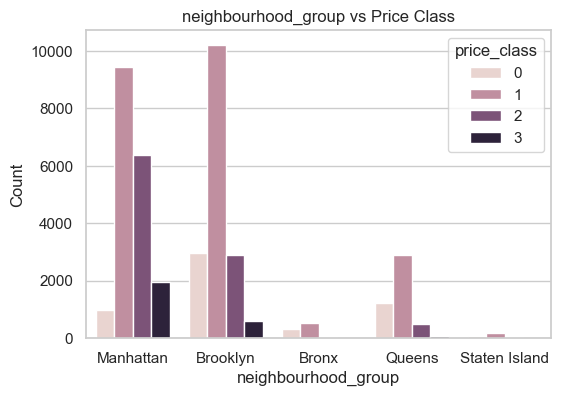

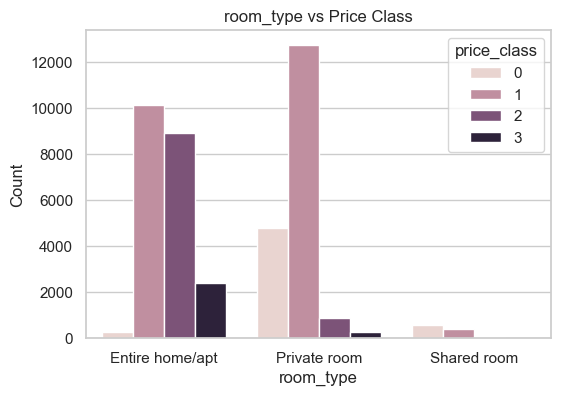

In [14]:
# now Feature vs Target Analysis
import matplotlib.pyplot as plt
import seaborn as sns

categorical_cols = ["neighbourhood_group", "room_type"]
for col in categorical_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue="price_class", data=df)
    plt.title(f"{col} vs Price Class")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()


### Observations
- Barplots show the distribution of price classes across categorical features.
- For example, Manhattan listings have more Premium and Luxury properties compared to Brooklyn or Queens. Moreover, it is also reflect through bar chats that moderate (1) dominates.

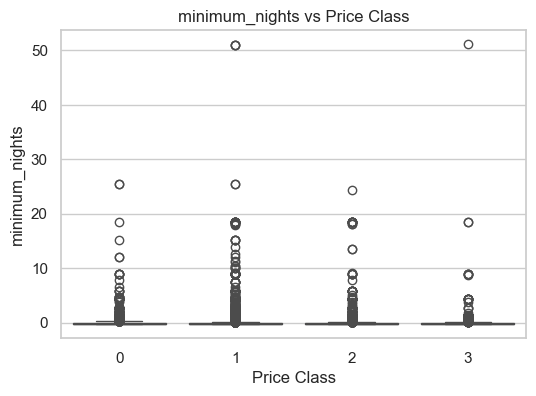

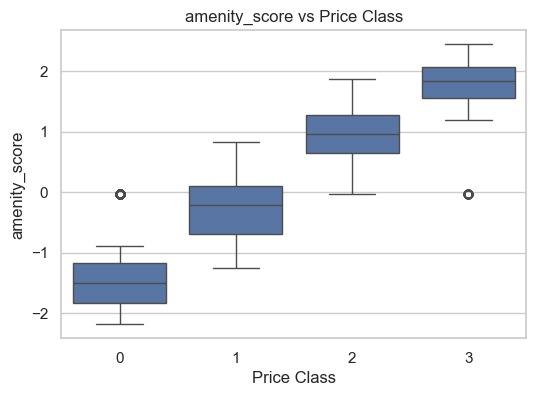

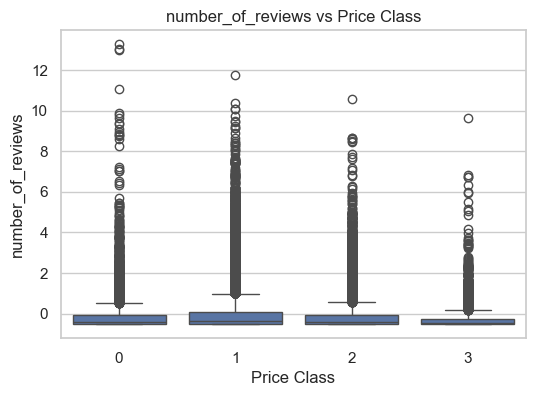

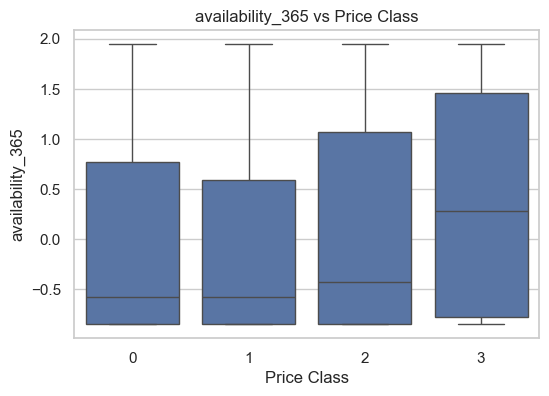

In [23]:
#Numeric features vs target
numerical_cols = ["minimum_nights", "amenity_score", "number_of_reviews", "availability_365"]

for col in numerical_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="price_class", y=col, data=df)
    plt.title(f"{col} vs Price Class")
    plt.xlabel("Price Class")
    plt.ylabel(col)
    plt.show()


### observation
Here we can see that in first plot, those who want to spend more nights or want to stay more wantedd to go to 1 moderate , while premium shows less night stays indicating business works or picnics.

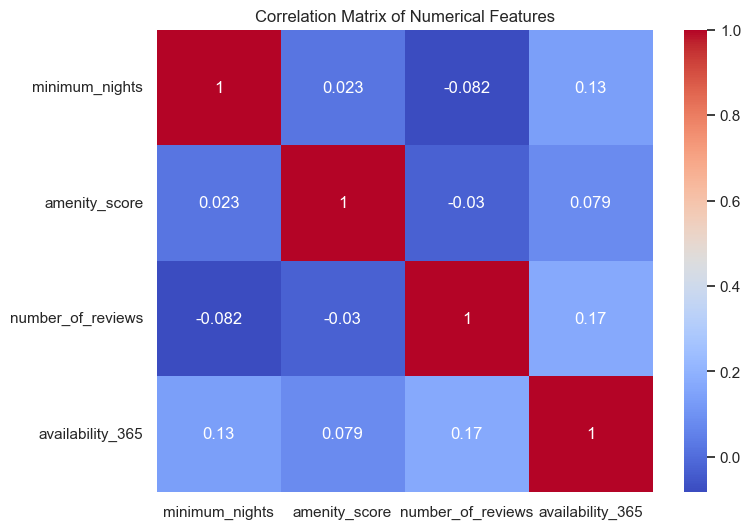

In [16]:
#correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix of Numerical Features")
plt.show()


### Observation
- amenity score and number of reviews have -ve corelation.
- minimum night and amenity score have 0.023 almost uncorelated 
- 1 important thing is that there are no extremely high correlations , so multicollinearity is not a major concern.   

In [24]:
# Correlation of numerical features with price_class
numeric_cols = ["minimum_nights", "amenity_score", "number_of_reviews", "availability_365"]

corr_with_target = df[numeric_cols + ["price_class"]].corr()["price_class"].sort_values(ascending=False)
print(corr_with_target)


price_class          1.000000
amenity_score        0.865352
availability_365     0.094887
minimum_nights       0.016005
number_of_reviews   -0.034259
Name: price_class, dtype: float64


amenity score comes out to be the most influential predictor.